# Radial mode solver examples

Each section builds a refractive-index profile, plots the 1D curve and the Cartesian map, then passes the 1D index to `RadialModeSolver`. The mode figure shows `|R|` against radius and the interpolated complex field for the fundamental mode and one mode with `L > 0`.


In [1]:
%matplotlib inline

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb
from matplotlib.patches import Circle
from IPython.display import display
from ipywidgets import IntSlider, Output

# The package root is algorithms/fibremodes, so algorithms/ must be on sys.path.
_start = Path.cwd().resolve()
for _folder in (_start, *_start.parents):
    if (_folder / "fibremodes" / "solvers" / "radialmodesolver.py").is_file():
        _algorithms = _folder
        break
    if _folder.name == "fibremodes" and (_folder / "solvers" / "radialmodesolver.py").is_file():
        _algorithms = _folder.parent
        break
    if (_folder / "algorithms" / "fibremodes" / "solvers" / "radialmodesolver.py").is_file():
        _algorithms = _folder / "algorithms"
        break
else:
    raise RuntimeError("Could not find the fibremodes package from the notebook working directory.")
if str(_algorithms) not in sys.path:
    sys.path.insert(0, str(_algorithms))

from fibremodes.solvers import DoubleClad, GradedIndex, RadialModeSolver, StepIndex


def complex_to_rgb(field):
    amplitude = np.abs(field)
    amplitude = amplitude / max(float(amplitude.max()), 1e-30)
    hue = (np.angle(field) + np.pi) / (2.0 * np.pi)
    hsv = np.stack([hue, np.ones_like(hue), amplitude], axis=-1)
    return hsv_to_rgb(hsv)


def show_modes(solver, cartesian, radii):
    window = float(solver.x[-1])
    extent = [-window * 1e6, window * 1e6, -window * 1e6, window * 1e6]
    with plt.ioff():
        fig, axes = plt.subplots(nrows=1, ncols=2, gridspec_kw={"width_ratios": [1, 1]})
    fig.set_size_inches(10, 5)

    radial = solver.modes[0]
    (line,) = axes[0].plot(solver.r_nodes * 1e6, np.abs(radial.R), color="black")
    axes[0].set_xlabel("Radius (µm)", fontsize=12)
    axes[0].set_ylabel("|R|", fontsize=12)
    axes[0].grid(visible=True, which="both", linestyle="--", linewidth=1)
    image = axes[1].imshow(complex_to_rgb(cartesian[0].field), extent=extent, origin="lower")
    axes[1].set_xlabel("x (µm)", fontsize=12)
    axes[1].set_ylabel("y (µm)", fontsize=12)
    for radius in radii:
        axes[0].axvline(radius * 1e6, color="0.4", linestyle="--", linewidth=1)
        if radius <= window:
            axes[1].add_patch(Circle(
                (0, 0), radius * 1e6,
                edgecolor="white", facecolor="none", linewidth=1.2,
            ))

    def update_mode(index):
        mode = cartesian[index]
        radial = solver.modes[index]
        amplitude = np.abs(radial.R)
        line.set_ydata(amplitude)
        peak = float(np.max(amplitude)) if amplitude.size else 1.0
        axes[0].set_ylim(0.0, peak * 1.05 if peak > 0.0 else 1.0)
        image.set_data(complex_to_rgb(mode.field))
        axes[0].set_title(rf"$L={mode.L}$, $M={mode.M}$, $\beta={mode.beta:.4f}$", fontsize=14)
        axes[1].set_title(rf"$L={mode.L}$, $M={mode.M}$", fontsize=14)
        with output:
            output.clear_output(wait=True)
            display(fig)

    output = Output()
    slider = IntSlider(min=0, max=len(cartesian) - 1, step=1, value=0, description="mode")
    slider.observe(lambda change: update_mode(change["new"]), names="value")
    display(slider, output)
    update_mode(0)


## Step index

Core diameter 50 µm, `n_core = 1.4585`, `NA = 0.22`, wavelength 1.55 µm.


(<Figure size 1000x500 with 2 Axes>,
 array([<Axes: title={'center': 'Refractive index'}, xlabel='x (µm)', ylabel='y (µm)'>,
        <Axes: title={'center': 'Refractive index profile'}, xlabel='Radius (µm)', ylabel='Refractive index'>],
       dtype=object))

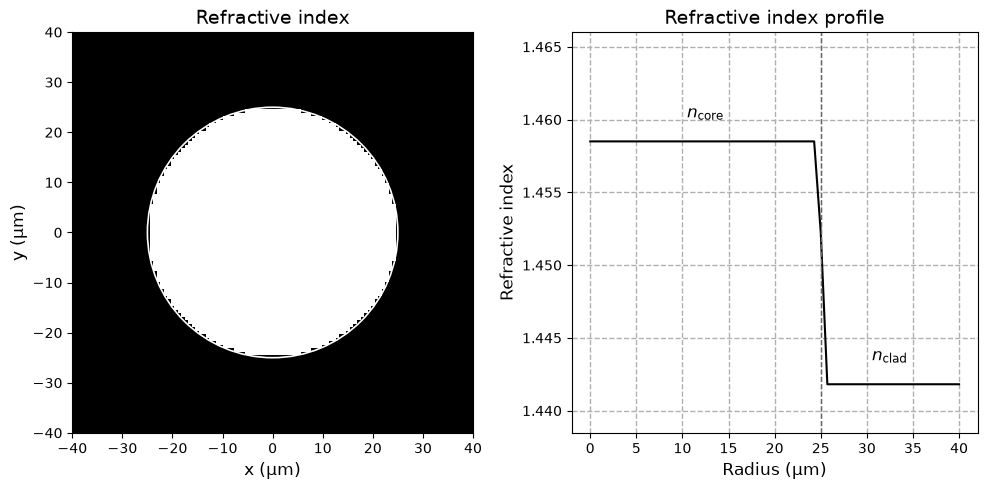

In [2]:
step = StepIndex(core_radius=25e-6, r_max=40e-6, n_core=1.4585, na=0.22, wavelength=1.55e-6)
r, n_r = step.index_1d(N=512)
step.plot()

In [7]:

solver = RadialModeSolver(r, n_r, wavelength=1.55e-6)
modes = solver.calculate_modes()
cartesian = solver.calculate_2d_modes(N=256)
print(f"{len(modes)} guided modes, highest |L| = {max(abs(mode.L) for mode in modes)}")


129 guided modes, highest |L| = 18


In [8]:
show_modes(solver, cartesian, step.boundary_radii())


IntSlider(value=0, description='mode', max=128)

Output()

## Graded index

Parabolic core of radius 31.25 µm, `n_core = 1.4666`, `NA = 0.275`, `alpha = 2`, wavelength 1565 nm.


153 guided modes, highest |L| = 16


IntSlider(value=0, description='mode', max=152)

Output()

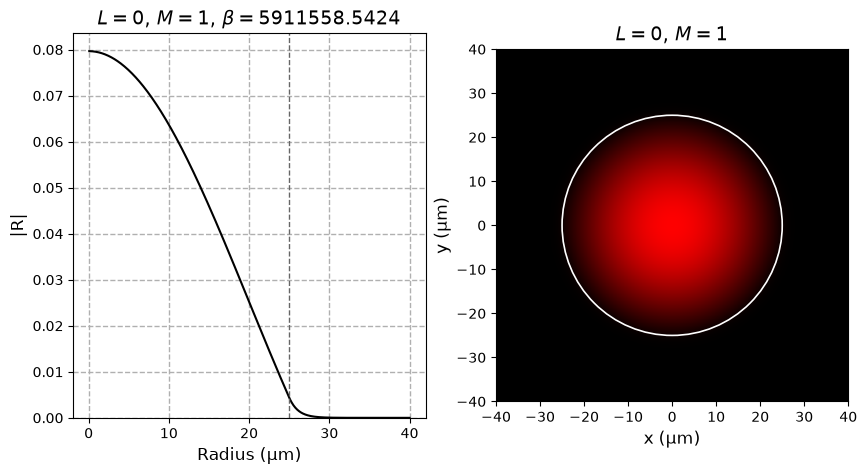

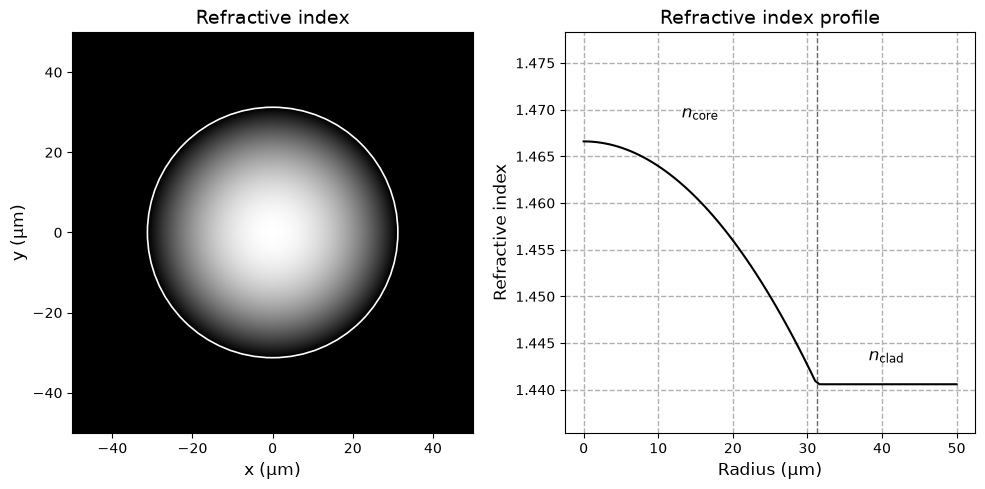

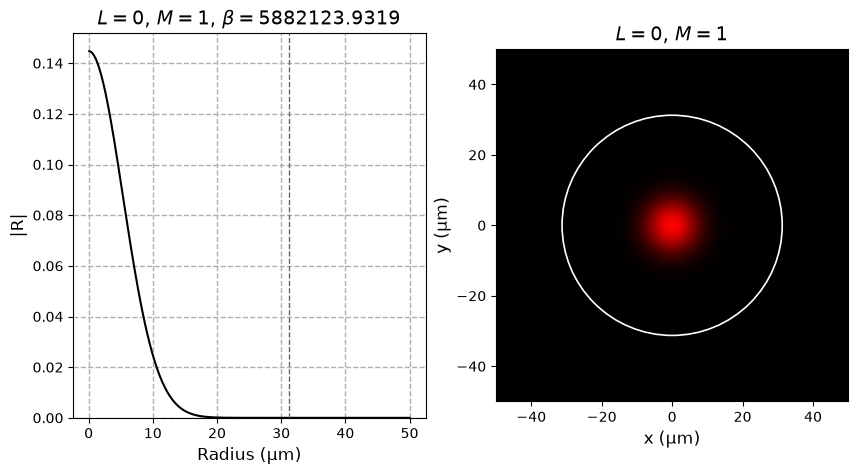

In [9]:
graded = GradedIndex(
    core_radius=31.25e-6, r_max=50e-6, n_core=1.4666, na=0.275, alpha=2,
    wavelength=1565e-9,
)
r, n_r = graded.index_1d(N=512)
graded.plot()

solver = RadialModeSolver(r, n_r, wavelength=1565e-9)
modes = solver.calculate_modes()
cartesian = solver.calculate_2d_modes(N=256)
print(f"{len(modes)} guided modes, highest |L| = {max(abs(mode.L) for mode in modes)}")
show_modes(solver, cartesian, graded.boundary_radii())


## Double clad

Diameters 4 µm, 23 µm and 125 µm. `n_core = 1.45841`, `NA_core = 0.13`, `NA_clad1 = 0.2`. The stored radial curve stops at twice the inner-cladding radius. Wavelength 843.5 nm.


(<Figure size 1000x500 with 2 Axes>,
 array([<Axes: title={'center': 'Refractive index'}, xlabel='x (µm)', ylabel='y (µm)'>,
        <Axes: title={'center': 'Refractive index profile'}, xlabel='Radius (µm)', ylabel='Refractive index'>],
       dtype=object))

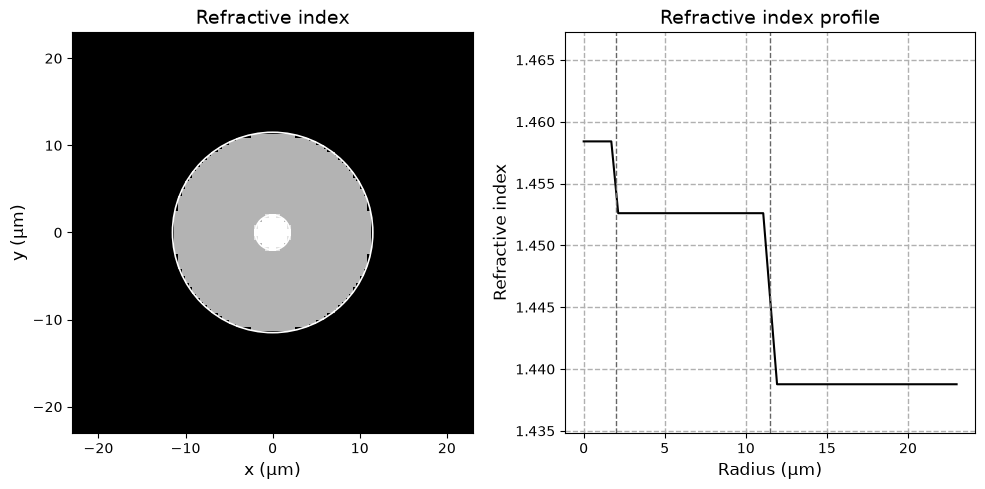

In [10]:
r_clad1 = 23e-6 / 2
double_clad = DoubleClad(
    core_radius=4e-6 / 2,
    clad1_radius=r_clad1,
    r_max=r_clad1 * 2,
    n_core=1.45841,
    na_core=0.13,
    na_clad1=0.2,
    wavelength=843.5e-9,
)
r, n_r = double_clad.index_1d(N=512)
double_clad.plot()


In [11]:
double_clad.boundary_radii()

(2e-06, 1.15e-05)

In [15]:

solver = RadialModeSolver(r, n_r, wavelength=843.5e-9)
modes = solver.calculate_modes()
cartesian = solver.calculate_2d_modes(N=256)
print(f"{len(modes)} guided modes, highest |L| = {max(abs(mode.L) for mode in modes)}")
show_modes(solver, cartesian, double_clad.boundary_radii())


76 guided modes, highest |L| = 13


IntSlider(value=0, description='mode', max=75)

Output()

In [16]:

# Resample onto a wider window without solving again. 100 µm is -100 µm to +100 µm.
wide = solver.calculate_2d_modes(N=256, window_max=100e-6)
print(f"resampled axis from {solver.x[0]*1e6:.0f} µm to {solver.x[-1]*1e6:.0f} µm, N = {len(solver.x)}")


resampled axis from -100 µm to 100 µm, N = 256


In [17]:
show_modes(solver, wide, double_clad.boundary_radii())


IntSlider(value=0, description='mode', max=75)

Output()

In [18]:
double_clad.boundary_radii()

(2e-06, 1.15e-05)